# Two MLPs for a binary target (0/1)
Model A: small MLP (like the example notebook). Model B: bigger MLP with dropout.
Both: ReLU hidden layers, sigmoid output, binary cross-entropy, mini-batch training with early stopping.

In [87]:
import numpy as np
import pandas as pd

In [88]:
def _doy365(date):
    """Dia do ano com 366 -> 365 (ano bissexto), como no cos de YDOY."""
    return np.minimum(date.dt.dayofyear.to_numpy(), 365)


def _learn_fills(train_val, strategy, doy_half_window):
    """Aprende, SÓ em train_val, as medianas usadas na imputação."""
    fill_cols = ["CHL_log", "CHL_uncertainty"]
    obs = train_val.dropna(subset=fill_cols)
    fills = {"global": obs[fill_cols].median()}
    if strategy == "season_median":
        fills["season"] = obs.groupby("Season")[fill_cols].median()
    if strategy == "doy_window_median":
        fills["obs_doy"] = _doy365(obs["Date"])
        fills["obs_vals"] = obs[fill_cols].to_numpy()
        fills["half_window"] = doy_half_window
    return fills


def _apply_fills(d, strategy, fills):
    """Preenche CHL_log e CHL_uncertainty em falta (imputação em log(CHL))."""
    d = d.copy()
    fill_cols = ["CHL_log", "CHL_uncertainty"]
    miss = d[fill_cols].isna().any(axis=1).to_numpy()
    if not miss.any():
        return d

    if strategy == "global_median":
        for c in fill_cols:
            d[c] = d[c].fillna(fills["global"][c])

    elif strategy == "season_median":
        for c in fill_cols:
            by_season = d["Season"].map(fills["season"][c])
            d[c] = d[c].fillna(by_season).fillna(fills["global"][c])

    elif strategy == "doy_window_median":
        doy = _doy365(d["Date"])
        for i in np.flatnonzero(miss):
            diff = np.abs(fills["obs_doy"] - doy[i])
            diff = np.minimum(diff, 365 - diff)           # distância circular
            in_win = diff <= fills["half_window"]
            for j, c in enumerate(fill_cols):
                if np.isnan(d[c].iloc[i]):
                    v = (np.median(fills["obs_vals"][in_win, j])
                         if in_win.any() else fills["global"][c])
                    d.iloc[i, d.columns.get_loc(c)] = v
    return d

def prepare_data(strategy, split_test, one_hot_cluster=True, sin_doy=True, test_frac=0.15, doy_half_window=15,
                 seed=42):
    """Prepara os dados do Task 1.

    Parâmetros
    ----------
    strategy : str, estratégia para os missing values (CHL, CHL_uncertainty)
        "drop_rows"         – remove linhas de train/val com missing
        "drop_features"     – remove CHL_log e CHL_uncertainty
        "global_median"     – mediana global (CHL em log)
        "season_median"     – mediana por estação do ano
        "doy_window_median" – mediana numa janela de ±doy_half_window dias
    split_test : str, forma de separar o conjunto de test
        "recent"     – 15% mais recentes, sem linhas com missing
        "stratified" – 15% do total, só linhas completas, espalhadas no tempo
                       e por estações, preservando a mistura de classes
    one_hot_cluster : bool – spatial_cluster -> 6 colunas 0/1
    sin_doy : bool – acrescenta sin(2π·DOY/365)

    Devolve
    -------
    (X_train_val, y_train_val, X_test, y_test)
    """

    # Read data
    df = pd.read_excel("classification_task1_train.xlsx")
    df["Date"] = pd.to_datetime(df["Date"])
    df = df.sort_values(["Date", "spatial_cluster"], kind="stable").reset_index(drop=True)


    # Separar os dados de test dos restantes dados
    if split_test == "recent":
        n_test = int(round(test_frac * len(df)))
        cutoff = df["Date"].iloc[len(df) - n_test]
        is_test = (df["Date"] >= cutoff).to_numpy()
        complete = df[["CHL", "CHL_uncertainty"]].notna().all(axis=1).to_numpy()
        test_mask = is_test & complete      # linhas completas do test
        rest_mask = ~is_test    

    else:
        rng = np.random.default_rng(seed)
        d = df.assign(_complete=df[["CHL", "CHL_uncertainty"]].notna().all(axis=1))

        by_date = d.groupby("Date").agg(n_rows=("HAB", "size"),
                                        all_complete=("_complete", "all"),
                                        hab=("HAB", "max"),
                                        season=("Season", "first"))
        elig = by_date[by_date["all_complete"]]

        n_target_dates = int(round(test_frac * len(df) / elig["n_rows"].mean()))
        n_target_dates = min(n_target_dates, len(elig))

        chosen = []
        for _, g in elig.groupby(["season", "hab"]):
            k = int(round(n_target_dates * len(g) / len(elig)))
            k = min(max(k, 1), len(g))                                        # >=1 data por estrato
            pos = ((rng.uniform() + np.arange(k)) * len(g) / k).astype(int)   # posições espaçadas
            chosen.extend(g.index[pos])

        test_mask = df["Date"].isin(chosen).to_numpy()    
        rest_mask = ~test_mask

    train_val, test = df[rest_mask].copy(), df[test_mask].copy()



    # log(CHL), sin_doy, one-hot do cluster
    # (aplicadas igualmente a train_val e test, para as colunas coincidirem) 
    # pode-se fazer isto porque não aprende nada
    train_val = train_val.copy()
    test = test.copy()
    train_val["CHL_log"] = np.log(train_val["CHL"]) 
    test["CHL_log"] = np.log(test["CHL"])                    
    if sin_doy:
        train_val["sin_doy"] = np.sin(2 * np.pi * _doy365(train_val["Date"]) / 365)
        test["sin_doy"] = np.sin(2 * np.pi * _doy365(test["Date"]) / 365)
    if one_hot_cluster:
        for c in range(6):                       
            train_val[f"cluster_{c}"] = (train_val["spatial_cluster"] == c).astype(int)
            test[f"cluster_{c}"] = (test["spatial_cluster"] == c).astype(int)


    # Estratégia para missing values (só para train_val, porque o test já é completo)
    if strategy == "drop_rows":
        train_val = train_val.dropna(subset=["CHL_log", "CHL_uncertainty"])
    elif strategy != "drop_features":
        fills = _learn_fills(train_val, strategy, doy_half_window)
        train_val = _apply_fills(train_val, strategy, fills)

    # Colunas finais (as restantes são redundantes e são descartadas)
    cols = ["Season", "SST", "UI", "YDOY"]
    if sin_doy:
        cols.append("sin_doy")
    if strategy != "drop_features":
        cols += ["CHL_log", "CHL_uncertainty"]
    cols += ([f"cluster_{c}" for c in range(6)]
             if one_hot_cluster else ["spatial_cluster"])

    assert not test[cols].drop(columns="Season").isna().any().any(), "test com NaN"
    assert not train_val[cols].isna().any().any(), "train_val com NaN"

    return (train_val[cols], train_val["HAB"],
            test[cols], test["HAB"])

In [89]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

import keras
from keras.models import Sequential
from keras.layers import Input, Dense, Dropout
from keras.callbacks import EarlyStopping, ModelCheckpoint

batch_size = 50
epochs = 150
lr = 0.001

In [90]:
X_train_val, y_train_val, X_test, y_test = prepare_data(strategy="season_median", split_test="stratified", one_hot_cluster=True, sin_doy=True)

X_train_val = X_train_val.drop(columns='Season')
X_test      = X_test.drop(columns='Season')

X_train_val.describe
X_test.describe

C:\Users\saraj\AppData\Local\Temp\ipykernel_4852\2498795292.py:3: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  return np.minimum(date.dt.dayofyear.to_numpy(), 365)
C:\Users\saraj\AppData\Local\Temp\ipykernel_4852\2498795292.py:3: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  return np.minimum(date.dt.dayofyear.to_numpy(), 365)


<bound method DataFrame.describe of         SST        UI      YDOY   sin_doy   CHL_log  CHL_uncertainty  \
14    13.25 -0.455750  0.004304  0.999991  1.579593        13.520000   
22    12.73  1.463944 -0.459733  0.888057  0.046555        21.160000   
29    12.90  0.676236 -0.671260  0.741222  0.664264        71.290001   
30    13.43  0.321047 -0.671260  0.741222  0.014675        66.379997   
32    13.46  0.140538 -0.755493  0.655156  0.408834        19.299999   
...     ...       ...       ...       ...       ...              ...   
1022  13.56  0.585003  0.209315 -0.977848  0.467445        19.000000   
1023  13.23  0.286482  0.209315 -0.977848  0.788597        51.259998   
1036  13.54  0.007593  0.651899 -0.758306  1.090370        15.809999   
1037  14.63  0.024676  0.651899 -0.758306  1.214130        15.170000   
1062  13.40  0.769815  0.999852 -0.017213  0.532183        18.670000   

      cluster_0  cluster_1  cluster_2  cluster_3  cluster_4  cluster_5  
14            1          0

In [91]:
print(len(X_train_val))        # number of rows
print(X_train_val.shape[0])   # also number of rows

903
903


In [92]:
# Continuous columns to scale (skip 0/1 columns)
num_cols = [X_train_val.columns.get_loc(c)
            for c in X_train_val.select_dtypes(include="number").columns
            if X_train_val[c].nunique() > 2]

X_train_val = X_train_val.to_numpy(dtype="float32")
X_test      = X_test.to_numpy(dtype="float32")

# Binary target: plain 0/1 vector (no one-hot needed)
y_train_val = np.asarray(y_train_val).ravel().astype("float32")
y_test      = np.asarray(y_test).ravel().astype("float32")

n_features = X_train_val.shape[1]
print("features:", n_features)
print("share of 1s -> train_val: %.3f | test: %.3f" % (y_train_val.mean(), y_test.mean()))

features: 12
share of 1s -> train_val: 0.123 | test: 0.169


In [93]:
# Validation split from train_val (test stays untouched)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.2, random_state=42, stratify=y_train_val)

# Scaling: fit on TRAIN only, continuous columns only
scaler = StandardScaler().fit(X_train[:, num_cols])
for A in (X_train, X_val, X_test):
    A[:, num_cols] = scaler.transform(A[:, num_cols])

# Baseline to beat: always predicting the majority class
base = max(y_val.mean(), 1 - y_val.mean())
print("Majority-class accuracy on validation: %.3f" % base)

# If classes are very imbalanced, set class_weight = {0: 1.0, 1: w} (e.g. w = n0/n1)
n0, n1 = (y_train == 0).sum(), (y_train == 1).sum()
class_weight = {0: 1.0, 1: n0 / n1}

Majority-class accuracy on validation: 0.878


In [94]:
def build_mlp(units, dropout=0.0, name="mlp"):
    m = Sequential(name=name)
    m.add(Input(shape=(n_features,)))
    for u in units:
        m.add(Dense(u, activation="relu"))
        if dropout > 0:
            m.add(Dropout(dropout))
    m.add(Dense(1, activation="sigmoid"))          # binary output
    m.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
              loss="binary_crossentropy",
              metrics=["accuracy", keras.metrics.AUC(name="auc")])
    return m

'''
def train(model, name):
    cbs = [EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True),
           ModelCheckpoint(f"best_{name}.keras", monitor="val_loss", save_best_only=True)]
    return model.fit(X_train, y_train, epochs=epochs, batch_size=batch_size,
                     validation_data=(X_val, y_val), callbacks=cbs,
                     class_weight=class_weight, verbose=1)

def train(model, name, n_epochs):
    cbs = [ModelCheckpoint(f"best_{name}.keras", monitor="val_loss", save_best_only=True)]
    return model.fit(X_train, y_train, epochs=n_epochs, batch_size=batch_size,
                     validation_data=(X_val, y_val), callbacks=cbs,
                     class_weight=class_weight, verbose=1)
'''


def train(model, name, n_epochs):
    cbs = [EarlyStopping(monitor="val_auc", mode="max", patience=20, restore_best_weights=True),
           ModelCheckpoint(f"best_{name}.keras", monitor="val_auc", mode="max", save_best_only=True)]
    return model.fit(X_train, y_train, epochs=n_epochs, batch_size=batch_size,
                     validation_data=(X_val, y_val), callbacks=cbs,
                     class_weight=None, verbose=1)


# Model A: small (like the example notebook)
model_A = build_mlp([16, 8], dropout=0.0, name="A_small")
# Model B: bigger + dropout
model_B = build_mlp([64, 32], dropout=0.3, name="B_big_dropout")

model_A.summary(); model_B.summary()


Model: "A_small"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_42 (Dense)                │ (None, 16)             │           208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_43 (Dense)                │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_44 (Dense)                │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 353 (1.38 KB)

 Trainable params: 353 (1.38 KB)

 Non-trainable params: 0 (0.00 B)

Model: "B_big_dropout"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_45 (Dense)                │ (None, 64)             │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_46 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_15 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_47 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,945 (11.50 KB)

 Trainable params: 2,945 (11.50 KB)

 Non-trainable params: 0 (0.00 B)

In [95]:
hist_A = train(model_A, "A_small", 150)         # exactly 26 epochs

Epoch 1/150
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - accuracy: 0.6690 - auc: 0.4801 - loss: 0.6571 - val_accuracy: 0.8177 - val_auc: 0.4743 - val_loss: 0.6250
Epoch 2/150
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8324 - auc: 0.4788 - loss: 0.5951 - val_accuracy: 0.8674 - val_auc: 0.4818 - val_loss: 0.5759
Epoch 3/150
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8767 - auc: 0.4906 - loss: 0.5434 - val_accuracy: 0.8785 - val_auc: 0.4920 - val_loss: 0.5304
Epoch 4/150
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8767 - auc: 0.5225 - loss: 0.4974 - val_accuracy: 0.8785 - val_auc: 0.5026 - val_loss: 0.4895
Epoch 5/150
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8767 - auc: 0.5635 - loss: 0.4570 - val_accuracy: 0.8785 - val_auc: 0.5227 - val_loss: 0.4558
Epoch 6/150
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8767 - auc: 0.5952 - loss: 0.4251 - val_accuracy: 0.8785 - val_auc: 0.5383 - val_loss: 0.4277
Epoch 7/150
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 

In [96]:

hist_B = train(model_B, "B_big_dropout", 250)   # exactly 80 epochs

Epoch 1/250
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - accuracy: 0.5319 - auc: 0.5228 - loss: 0.6948 - val_accuracy: 0.8619 - val_auc: 0.4438 - val_loss: 0.5762
Epoch 2/250
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8158 - auc: 0.4706 - loss: 0.5397 - val_accuracy: 0.8785 - val_auc: 0.4148 - val_loss: 0.4703
Epoch 3/250
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8657 - auc: 0.4519 - loss: 0.4652 - val_accuracy: 0.8785 - val_auc: 0.4583 - val_loss: 0.4114
Epoch 4/250
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8767 - auc: 0.5134 - loss: 0.4127 - val_accuracy: 0.8785 - val_auc: 0.5559 - val_loss: 0.3764
Epoch 5/250
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.8781 - auc: 0.5707 - loss: 0.3862 - val_accuracy: 0.8785 - val_auc: 0.6770 - val_loss: 0.3563
Epoch 6/250
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.8767 - auc: 0.6142 - loss: 0.3765 - val_accuracy: 0.8785 - val_auc: 0.7476 - val_loss: 0.3410
Epoch 7/250
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s

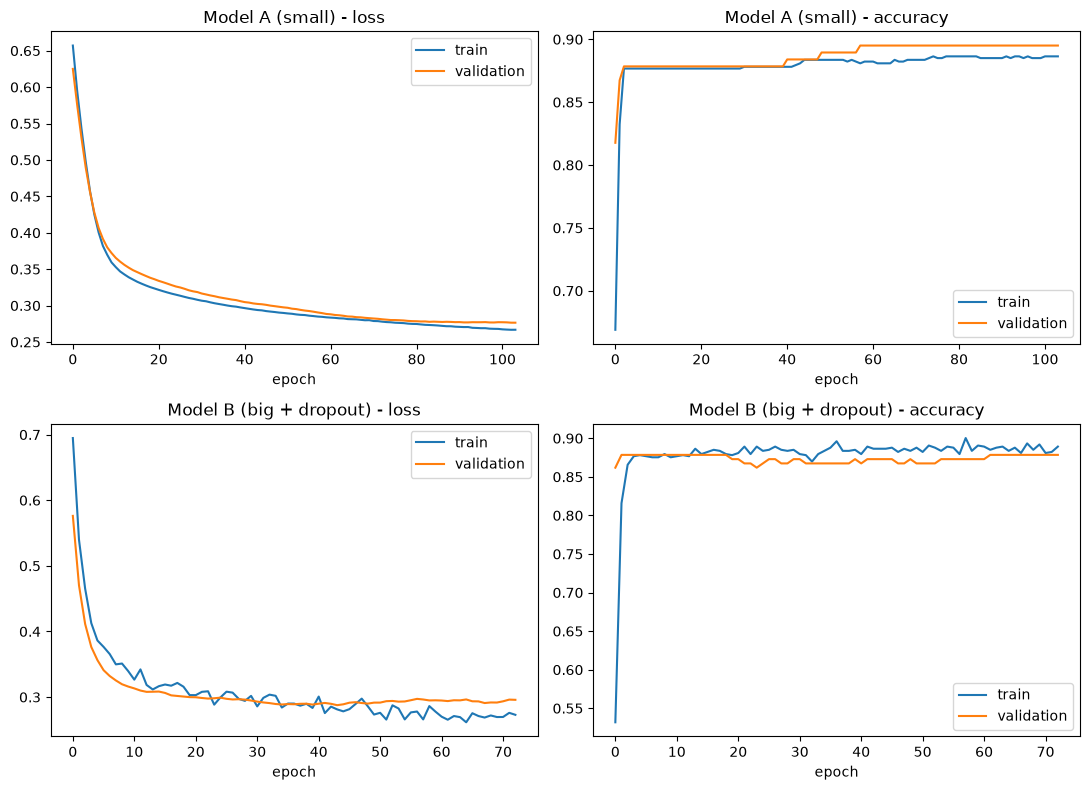

In [97]:
# Training curves = overfitting check (train vs validation gap)
fig, ax = plt.subplots(2, 2, figsize=(11, 8))
for row, (h, title) in enumerate([(hist_A, "Model A (small)"), (hist_B, "Model B (big + dropout)")]):
    ax[row, 0].plot(h.history["loss"], label="train")
    ax[row, 0].plot(h.history["val_loss"], label="validation")
    ax[row, 0].set_title(title + " - loss"); ax[row, 0].set_xlabel("epoch"); ax[row, 0].legend()
    ax[row, 1].plot(h.history["accuracy"], label="train")
    ax[row, 1].plot(h.history["val_accuracy"], label="validation")
    ax[row, 1].set_title(title + " - accuracy"); ax[row, 1].set_xlabel("epoch"); ax[row, 1].legend()
plt.tight_layout(); plt.show()

In [98]:
def evaluate(model, X, y, label):
    p = model.predict(X, verbose=0).ravel()
    pred = (p >= 0.5).astype(int)
    acc = (pred == y).mean()
    auc = roc_auc_score(y, p)
    print(f"{label}: accuracy={acc:.4f} | AUC={auc:.4f}")
    return pred, acc, auc

rows = []
for name, m in [("A_small", model_A), ("B_big_dropout", model_B)]:
    _, va, vauc = evaluate(m, X_val, y_val, f"{name} VALIDATION")
    rows.append((name, va, vauc))
print()
print("Pick the model using the VALIDATION numbers above, then look at the test set:")
print()

for name, m in [("A_small", model_A), ("B_big_dropout", model_B)]:
    pred, _, _ = evaluate(m, X_test, y_test, f"{name} TEST")
    print(classification_report(y_test, pred, digits=3))
    print("Confusion matrix (rows = true 0/1, cols = predicted 0/1):")
    print(confusion_matrix(y_test, pred)); print()

A_small VALIDATION: accuracy=0.8950 | AUC=0.8439
B_big_dropout VALIDATION: accuracy=0.8674 | AUC=0.8313

Pick the model using the VALIDATION numbers above, then look at the test set:

A_small TEST: accuracy=0.8187 | AUC=0.7925
              precision    recall  f1-score   support

         0.0      0.833     0.977     0.900       133
         1.0      0.250     0.037     0.065        27

    accuracy                          0.819       160
   macro avg      0.542     0.507     0.482       160
weighted avg      0.735     0.819     0.759       160

Confusion matrix (rows = true 0/1, cols = predicted 0/1):
[[130   3]
 [ 26   1]]

B_big_dropout TEST: accuracy=0.8250 | AUC=0.8109
              precision    recall  f1-score   support

         0.0      0.857     0.947     0.900       133
         1.0      0.462     0.222     0.300        27

    accuracy                          0.825       160
   macro avg      0.659     0.585     0.600       160
weighted avg      0.790     0.825     0.799